# Predicción de llamadas al 911 — Demo de resultados

**Proyección 2026–2028 · datos históricos 2018–2025**

Este notebook es una **demo de solo lectura**: viene con todas las salidas y figuras ya
calculadas, así que se puede revisar sin ejecutar nada ni configurar nada.

---

## Qué se hizo en este trabajo

Se revisó y actualizó el pipeline original de predicción (SARIMAX) a partir de tres frentes:

| Frente | Resultado |
|---|---|
| **Entorno y conexión** | La conexión a SQL Server estaba rota: TCP/IP deshabilitado y la instancia sin certificado TLS. Corregido y verificado. |
| **Actualización temporal** | El histórico pasó a **2018–2025** (8 años, 96 meses) y la proyección a **36 meses: 2026, 2027 y 2028**. |
| **Clasificadores** | **DVP** (Desorden en la Vía Pública, ID 4) y **VG** (Violencia de Género, ID 8), reentrenados y proyectados. |

## Qué se puede ver aquí

1. **Los datos**: cobertura, totales por año y validación contra la base de datos.
2. **El método**: serie mensual, descomposición estacional y elección del modelo por AIC.
3. **Un hallazgo real**: el AIC solo elegía en VG un modelo *degenerado*, y se corrigió.
4. **La validación honesta**: error medido sobre 2024–2025, años que el modelo nunca vio.
5. **La proyección 2026–2028** de las tres series, con intervalo al 95 %.

> **Cómo leer las cifras:** la unidad de trabajo es el **promedio diario de llamadas
> dentro del mes**. Para el total del mes se multiplica por los días que tenga.


## 1. Los datos

Tres series históricas diarias, **2018-01-01 a 2025-12-31**:

| Serie | Descripción |
|---|---|
| General | Todas las llamadas al 911 |
| DVP (ID 4) | Desorden en la vía pública y/o privada |
| VG (ID 8) | Violencia familiar – mujer agredida |

Los datos se extrajeron de SQL Server (`DW2026`, esquema `DW`) y se validaron contra la base:
los totales anuales **coinciden exactamente** con la consulta directa.


In [3]:
# ============================================================================
# 0) PREPARACION DEL ENTORNO (solo hace algo en Google Colab)
# ============================================================================
# Se monta Drive ANTES de cargar los datos. Es imprescindible: al abrir un
# notebook desde Drive, Colab NO usa la carpeta del notebook como directorio de
# trabajo (suele ser /content), asi que sin montar Drive los CSV no existen.
import os
import sys
import warnings

warnings.filterwarnings("ignore")

EN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
RAIZ_DRIVE = "/content/drive/MyDrive"


def _drive_listo():
    """Comprueba de verdad que 'Mi unidad' es accesible, no solo que exista
    la carpeta de montaje: un montaje a medias deja /content/drive vacio."""
    return os.path.isdir(RAIZ_DRIVE) and len(os.listdir(RAIZ_DRIVE)) > 0


if EN_COLAB:
    try:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            print("Montando Google Drive (autoriza en la ventana si te lo pide)...")
            drive.mount("/content/drive", force_remount=False)

        if _drive_listo():
            print("Drive montado y accesible.")
            nivel1 = sorted(d for d in os.listdir(RAIZ_DRIVE)
                            if os.path.isdir(os.path.join(RAIZ_DRIVE, d)))[:12]
            print("  Carpetas en 'Mi unidad':", nivel1)
            print("  La demo buscara los CSV en cualquier subcarpeta de 'Mi unidad'.")
        else:
            print("[AVISO] Drive NO quedo accesible en", RAIZ_DRIVE)
            print("        Suele pasar cuando no se autorizo el acceso. Solucion:")
            print("          from google.colab import drive; drive.mount('/content/drive', force_remount=True)")
            print("        y acepta la autorizacion. Si no, la demo te dejara subir los CSV a mano.")
    except Exception as exc:
        print("[AVISO] no se pudo montar Drive:", exc)
        print("        Se ofrecera la subida manual al cargar los datos.")
else:
    print("Entorno local: no hace falta montar Drive.")


Entorno local: no hace falta montar Drive.


In [4]:
# ============================================================================
# 1) CARGA DE DATOS
# ============================================================================
# Busca los 3 CSV de forma robusta:
#   1) junto al notebook (local, y Colab abierto desde Drive),
#   2) si no, en CUALQUIER carpeta de 'Mi unidad' (la demo puede estar en
#      cualquier subcarpeta: 'Colab Notebooks/prediccion_demo', etc.),
#   3) y como ultimo recurso ofrece subirlos a mano.
# Ojo: al abrir un notebook desde Drive, Colab NO usa la carpeta del notebook
# como directorio de trabajo (suele ser /content), por eso no basta con mirar
# en la carpeta actual.
import os
import sys
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm

try:                                    # si se ejecuta en Jupyter/Colab
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

print("pandas", pd.__version__, "| numpy", np.__version__, "| statsmodels", sm.__version__)

# El proyecto esta verificado con statsmodels 0.14.4 y pandas < 3. Otras versiones
# pueden funcionar, pero conviene saberlo si los resultados no cuadran con la
# entrega. Este aviso no detiene la demo.
try:
    _v_sm = tuple(int(x) for x in sm.__version__.split(".")[:2])
    _v_pd = tuple(int(x) for x in pd.__version__.split(".")[:1])
    if _v_sm != (0, 14):
        print(f"  [AVISO] statsmodels {sm.__version__} distinta de la verificada (0.14.4).")
        print("          La demo deberia funcionar, pero las cifras pueden variar en decimales.")
    if _v_pd >= (3,):
        print(f"  [AVISO] pandas {pd.__version__} es 3.x: statsmodels no lo soporta bien.")
        print("          Ejecuta:  !pip install -q 'pandas<3'  y reinicia el entorno.")
except Exception:
    pass

SERIES = ["general", "dvp", "vg"]
ETIQUETA = {"general": "General (todas las llamadas)",
            "dvp": "DVP (ID 4) - Desorden via publica",
            "vg": "VG (ID 8) - Violencia familiar"}

EN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
RAIZ_DRIVE = "/content/drive/MyDrive"


def _drive_accesible():
    """True si 'Mi unidad' existe y tiene contenido.

    Se redefine aqui (y no se reutiliza la de la celda 0) para que esta celda
    funcione aunque se ejecute suelta, sin haber corrido antes la celda 0.
    """
    return os.path.isdir(RAIZ_DRIVE) and len(os.listdir(RAIZ_DRIVE)) > 0


def _carpetas_candidatas():
    """Carpetas probables donde estan los CSV, de la mas a la menos probable."""
    cwd = os.getcwd()
    carpetas = [
        cwd,                                   # local / Colab abierto desde Drive
        os.path.join(cwd, "data"),
        os.path.join(cwd, os.pardir, "data"),
        os.environ.get("PREDICCION_DATA_DIR", ""),
        "/content",                            # raiz de trabajo de Colab
        "/content/drive/MyDrive/Colab Notebooks/prediccion_demo",
        "/content/drive/MyDrive/prediccion_demo",
        "/content/drive/MyDrive/prediccion/data",
    ]
    return [c for c in carpetas if c]


def _buscar_en_drive(nombre):
    """Recorre 'Mi unidad' buscando el CSV, en cualquier subcarpeta.

    Devuelve la lista de coincidencias exactas y tambien las que empiezan por el
    nombre pedido (Drive anade sufijos como 'datos_general (1).csv' cuando se
    sube un archivo que ya existe).
    """
    raiz = "/content/drive/MyDrive"
    if not os.path.isdir(raiz):
        print(f"  [DIAGNOSTICO] '{raiz}' no existe: Drive no esta montado.")
        print("                Ejecuta la celda 0 y autoriza el acceso a Drive.")
        return []
    base = nombre[:-4] if nombre.lower().endswith(".csv") else nombre
    exactos, parecidos = [], []
    for actual, dirs, ficheros in os.walk(raiz):
        dirs[:] = [d for d in dirs if not d.startswith(".")]
        for f in ficheros:
            if f == nombre:
                exactos.append(os.path.join(actual, f))
            elif f.lower().startswith(base.lower()) and f.lower().endswith(".csv"):
                parecidos.append(os.path.join(actual, f))
        if len(exactos) >= 5:
            break
    return exactos + parecidos


def _leer(ruta):
    df = pd.read_csv(ruta)
    df["FECHA"] = pd.to_datetime(df["FECHA"])
    return df.sort_values("FECHA").reset_index(drop=True), os.path.abspath(ruta)


def _subir_a_mano(nombre):
    """Ultimo recurso: subir el CSV a mano y validar que es el correcto."""
    archivo = f"datos_{nombre}.csv"
    print(f"No se encontro '{archivo}' en Drive. Sube los 3 CSV ahora:")
    try:
        from google.colab import files
        subidos = files.upload()
    except Exception as exc:
        print("  subida manual no disponible:", exc)
        return None

    if not subidos:
        print("  no se subio ningun archivo.")
        return None

    # Puede llegar con otro nombre (p. ej. 'datos_general (1).csv'): se comprueba
    # el contenido en vez de fiarse del nombre.
    for nombre_subido in subidos:
        if os.path.exists(nombre_subido):
            try:
                df, ruta = _leer(nombre_subido)
                print(f"  subido: {nombre_subido} ({len(df)} filas)")
                return df, ruta
            except Exception as exc:
                print(f"  [AVISO] '{nombre_subido}' no parece un CSV valido: {exc}")
    return None


def cargar(nombre):
    """Carga un CSV probando ubicaciones, buscando en Drive o subiendolo a mano."""
    archivo = f"datos_{nombre}.csv"

    for carpeta in _carpetas_candidatas():
        ruta = os.path.join(carpeta, archivo)
        if os.path.exists(ruta):
            return _leer(ruta)

    if EN_COLAB:
        # Reintento del montaje: si la celda 0 no dejo Drive accesible (por
        # ejemplo si no se autorizo), se vuelve a intentar aqui, que es donde
        # realmente hace falta, antes de rendirse y pedir los archivos a mano.
        if not _drive_accesible():
            print("Drive no esta accesible; reintentando el montaje...")
            try:
                from google.colab import drive
                drive.mount("/content/drive", force_remount=True)
            except Exception as exc:
                print("  no se pudo montar:", exc)

        print(f"'{archivo}' no esta junto al notebook; buscando en 'Mi unidad'...")
        hallados = _buscar_en_drive(archivo)
        if hallados:
            print(f"  encontrado en: {hallados[0]}")
            if len(hallados) > 1:
                print(f"  [AVISO] hay {len(hallados)} copias; se usa la primera:")
                for h in hallados[1:]:
                    print(f"          {h}")
            return _leer(hallados[0])

        subido = _subir_a_mano(nombre)
        if subido is not None:
            return subido

    raise FileNotFoundError(
        f"No se encontro '{archivo}'.\n"
        "  En local: debe estar en la MISMA carpeta que este notebook.\n"
        "  En Colab: sube los 3 CSV a 'Mi unidad' (sirve cualquier subcarpeta, "
        "por ejemplo 'Colab Notebooks/prediccion_demo') y vuelve a ejecutar.")


datos, origenes = {}, {}
for n in SERIES:
    df, org = cargar(n)
    df["anio"] = df["FECHA"].dt.year
    datos[n] = df
    origenes[n] = org
    print(f"  {n:8s} {len(df):5d} dias | {df['FECHA'].min():%Y-%m-%d} -> {df['FECHA'].max():%Y-%m-%d} | {org}")

print("\nTotales de llamadas por anio (validados contra la base de datos):")
tabla = pd.DataFrame({ETIQUETA[n].split(" (")[0]: datos[n].groupby("anio")["CANTIDAD"].sum()
                      for n in SERIES})
tabla.index.name = "anio"
tabla


pandas 2.3.3 | numpy 2.2.6 | statsmodels 0.14.4
  general   2922 dias | 2018-01-01 -> 2025-12-31 | C:\Prediccion2026\demo\datos_general.csv
  dvp       2922 dias | 2018-01-01 -> 2025-12-31 | C:\Prediccion2026\demo\datos_dvp.csv
  vg        2919 dias | 2018-01-01 -> 2025-12-31 | C:\Prediccion2026\demo\datos_vg.csv

Totales de llamadas por anio (validados contra la base de datos):


,General,DVP,VG
anio,,,
2018,178765.0,19559.0,4206.0
2019,162065.0,14756.0,3745.0
2020,178791.0,10801.0,4061.0
2021,136841.0,14150.0,4078.0
2022,117133.0,11407.0,3676.0
2023,127662.0,11751.0,3642.0
2024,121677.0,12078.0,3846.0
2025,125475.0,13558.0,4513.0


  general  96 meses | min= 202.8  media= 393.3  max= 635.4
  dvp      96 meses | min=  15.6  media=  37.0  max=  64.6
  vg       96 meses | min=   7.2  media=  10.9  max=  15.9
  general  2023-08:    nan ->  361.9 llamadas/dia (agostos vecinos: 2020-08=424.8, 2021-08=350.3, 2022-08=310.7)
  general  2024-08:    nan ->  330.5 llamadas/dia (agostos vecinos: 2021-08=350.3, 2022-08=310.7)
  general  2025-08:    nan ->  310.7 llamadas/dia (agostos vecinos: 2022-08=310.7)
  dvp      2023-08:    nan ->   24.7 llamadas/dia (agostos vecinos: 2020-08=18.9, 2021-08=29.4, 2022-08=25.9)
  dvp      2024-08:    nan ->   27.6 llamadas/dia (agostos vecinos: 2021-08=29.4, 2022-08=25.9)
  dvp      2025-08:    nan ->   25.9 llamadas/dia (agostos vecinos: 2022-08=25.9)
  vg       2023-08:    nan ->    9.5 llamadas/dia (agostos vecinos: 2020-08=8.6, 2021-08=10.6, 2022-08=9.4)
  vg       2024-08:    nan ->   10.0 llamadas/dia (agostos vecinos: 2021-08=10.6, 2022-08=9.4)
  vg       2025-08:    nan ->    9.4 l

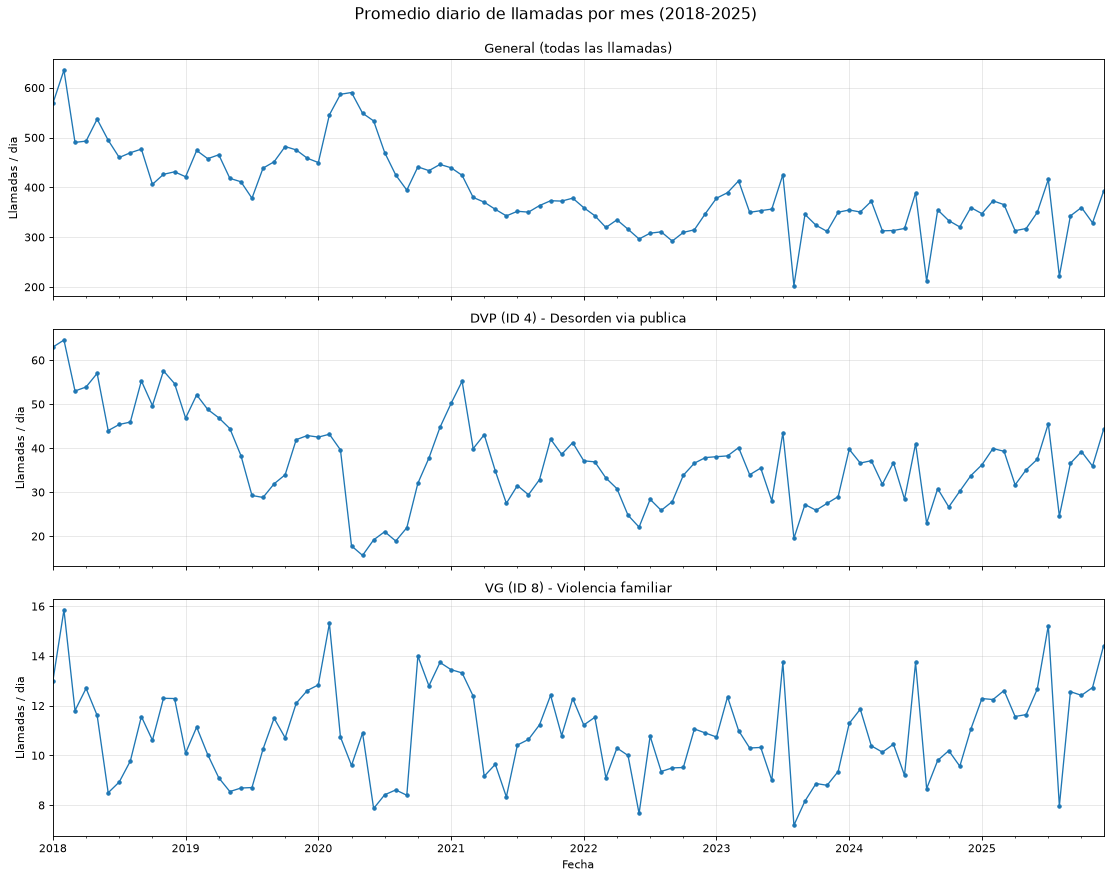

In [5]:
# ============================================================================
# 2) SERIE MENSUAL DE TRABAJO
# ============================================================================
# El pipeline no modela el dato diario, sino el PROMEDIO DIARIO de cada mes.
# Esa agregacion quita el ruido de fin de semana y hace la serie estacionalmente
# tratable con 96 observaciones (8 ciclos anuales completos).
series = {}
for n in SERIES:
    s = datos[n].set_index("FECHA")["CANTIDAD"].resample("MS").mean()
    series[n] = s
    print(f"  {n:8s} {len(s)} meses | min={s.min():6.1f}  media={s.mean():6.1f}  max={s.max():6.1f}")

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, n in zip(axes, SERIES):
    series[n].plot(ax=ax, marker="o", markersize=3, linewidth=1.2, color="#1f77b4")
    ax.set_title(ETIQUETA[n], fontsize=12)
    ax.set_ylabel("Llamadas / dia")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Fecha")
fig.suptitle("Promedio diario de llamadas por mes (2018-2025)", fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

# --- correccion de calidad: agosto 2023-2025 --------------------------------
# Agosto se hunde solo en 2023, 2024 y 2025 (203, 212 y 222 llamadas/dia frente a
# 310-470 de los anios previos), y NO es un problema del pipeline: se verifico en
# el origen (una fila = una llamada) y coincide mes a mes con el DW. Es un
# artefacto del sistema de origen, y el detector automatico no lo ve porque su
# referencia (+-6 meses) se deprime con los tres agostos.
#
# Se excluyen y se reconstruyen con el MISMO mes de anios vecinos: la
# interpolacion lineal romperia la estacionalidad (agosto = mezcla de jul y sep).
MESES_AGOSTO = ["2023-08", "2024-08", "2025-08"]
for n in SERIES:
    s = series[n]
    # Se promedia el MISMO mes (agosto) de anios vecinos, nunca meses contiguos:
    # eso convertiria agosto en una mezcla de julio y septiembre y falsearia el
    # patron estacional.
    #
    # Dos pasadas: primero se calculan todos los valores con la referencia
    # original (los agostos no descartados) y despues se asignan. Si se asignara
    # sobre la marcha, una imputacion dependeria de otra.
    agostos_reales = s[s.index.month == 8]
    # Se marcan como nulos para que la referencia NUNCA incluya un valor ya
    # reconstruido, sea cual sea el orden de tratamiento.
    for marca in MESES_AGOSTO:
        f = pd.Timestamp(marca + "-01")
        if f in s.index:
            s[f] = np.nan
    calculados = {}
    for marca in MESES_AGOSTO:
        f = pd.Timestamp(marca + "-01")
        if f not in agostos_reales.index:
            continue
        # Referencia: el MISMO mes (agosto) de los 3 anos anteriores y posteriores.
        # Se busca por ANO CALENDARIO, no por posicion en la serie: al estar los
        # agostos excluidos como NaN, desplazarse por posiciones caeria en meses
        # contiguos (mayo-julio, septiembre-noviembre) y falsearia el patron.
        vecinos = []
        for k in (-3, -2, -1, 1, 2, 3):
            g = pd.Timestamp(f"{f.year + k}-08-01")
            v = s.get(g)
            if pd.notna(v):
                vecinos.append((g, v))
        if vecinos:
            calculados[f] = (float(np.mean([v for _, v in vecinos])), vecinos)

    for f, (valor, vecinos) in calculados.items():
        etiquetas = ", ".join(f"{fa:%Y-%m}={va:.1f}" for fa, va in vecinos)
        print(f"  {n:8s} {f:%Y-%m}: {s[f]:6.1f} -> {valor:6.1f} llamadas/dia "
              f"(agostos vecinos: {etiquetas})")
        s[f] = valor
    series[n] = s

print("\nPeso del componente estacional (descomposicion aditiva):")
for n in SERIES:
    d = sm.tsa.seasonal_decompose(series[n], model="additive")
    peso = d.seasonal.var() / (d.seasonal.var() + d.resid.var()) * 100
    print(f"  {n:8s} estacional={peso:5.1f}%  de la varianza no tendencial")


## 3. Elección del modelo: la rejilla AIC y un hallazgo real

El procedimiento del proyecto original se respeta: se prueban las **64 combinaciones**
`(p,d,q) × (P,D,Q,12)` con `p,d,q,P,D,Q ∈ {0,1}` y se elige el **menor AIC**, entrenando
solo con 2018–2023 para reservar 2024–2025 como validación.

### El hallazgo

Al ejecutarlo, el AIC eligió para **VG** este modelo:

```
SARIMAX(1,1,1) x (0,1,1,12)
   ma.L1   = -1.0000   (error estandar 788)
   sigma2  =  2.3004   (error estandar 1813)
```

`ma.L1 = -1.0000` está **clavado en el límite de invertibilidad**. Eso no es un modelo
estimable: los errores estándar explotan y la varianza de innovación colapsa, así que el
pronóstico y su intervalo no son fiables. **El AIC por sí solo no lo detecta.**

### La corrección

Se añadió un filtro numérico que descarta los ajustes degenerados (parámetros AR/MA con
`|coef| > 0.999`, o `sigma2` colapsado).

### Y una segunda corrección: cómo se elige entre los válidos

El AIC mide el ajuste **dentro** de la muestra, y tendía a elegir modelos con diferenciación
regular (`d=1`). En una serie con tendencia, `d=1` equivale a extrapolar el último incremento
observado, así que el pronóstico se desviaba hacia arriba de forma sistemática: en DVP
llegaba a predecir la mitad del valor real.

Ahora, de los **5 mejores por AIC** se elige el de **menor RMSE de validación cruzada**
(ventanas móviles, que se explican en la sección 4). La celda anterior imprime los finalistas
con su AIC, su RMSE de validación y su sesgo, para que la elección quede a la vista.


In [7]:
# ============================================================================
# 3) BUSQUEDA AIC CON FILTRO DE AJUSTES DEGENERADOS
# ============================================================================
import itertools

ANIO_HOLDOUT = 2024


def ajuste_es_utilizable(res, serie, umbral=0.999):
    """Descarta ajustes con parametros AR/MA en el limite de estacionariedad.

    Un coeficiente pegado a +-1 no es estimable: su error estandar explota y la
    varianza de innovacion colapsa. El AIC por si solo puede premiar ese ajuste.
    """
    nombres = list(res.param_names)
    valores = np.asarray(res.params, dtype=float)
    if not np.all(np.isfinite(valores)):
        return False, "parametros no finitos"
    for nombre, valor in zip(nombres, valores):
        if nombre.startswith(("ar.", "ma.")) and abs(valor) > umbral:
            return False, f"{nombre} clavado en el limite ({valor:.4f})"
    if "sigma2" in nombres:
        sigma2 = float(valores[nombres.index("sigma2")])
        var_serie = float(np.nanvar(np.asarray(serie, dtype=float)))
        if not np.isfinite(sigma2) or sigma2 <= 0:
            return False, f"sigma2 no valido ({sigma2})"
        if var_serie > 0 and sigma2 / var_serie < 1e-6:
            return False, "sigma2 casi nulo"
    return True, ""


resultados = {}
VENTANA_CV = 12
MIN_ENTRENAMIENTO = 36


def cv_rolling(serie, orden, seas, horizonte=VENTANA_CV, minimo=MIN_ENTRENAMIENTO):
    """RMSE, MAE y sesgo con ventanas moviles sobre el bloque completo.

    Para cada origen se entrena solo con el pasado y se proyecta la ventana
    siguiente: no hay fuga de informacion y todo el bloque actua como prueba.
    """
    errs, reales = [], []
    for corte in range(minimo, len(serie) - horizonte + 1):
        try:
            r = sm.tsa.statespace.SARIMAX(
                serie.iloc[:corte], order=orden, seasonal_order=seas,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            pred = r.get_forecast(steps=horizonte).predicted_mean
            real = serie.iloc[corte:corte + horizonte]
            errs.extend((real.values - pred.values).tolist())
            reales.extend(real.values.tolist())
        except Exception:
            continue
    if not errs:
        return None
    e = np.array(errs, dtype=float)
    r_ = np.array(reales, dtype=float)
    nz = r_ != 0
    return dict(n=len(e),
                rmse=float(np.sqrt(np.mean(e ** 2))),
                mae=float(np.mean(np.abs(e))),
                mape=float(np.mean(np.abs(e[nz] / r_[nz])) * 100),
                sesgo=float(np.mean(e)))


for n in SERIES:
    serie = series[n]

    validos, degenerados = [], []
    for param in itertools.product(range(2), repeat=3):
        for seas in [(P, D, Q, 12) for P in range(2) for D in range(2) for Q in range(2)]:
            try:
                res = sm.tsa.statespace.SARIMAX(
                    serie, order=param, seasonal_order=seas,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            except Exception:
                continue
            ok, motivo = ajuste_es_utilizable(res, serie)
            (validos if ok else degenerados).append((float(res.aic), param, seas, motivo))

    validos.sort(key=lambda x: x[0])
    degenerados.sort(key=lambda x: x[0])

    print(f"\n{n.upper()}  ({len(validos) + len(degenerados)} combinaciones evaluadas)")
    print(f"  validos={len(validos)}  descartados por degenerados={len(degenerados)}")
    for aic, par, se, motivo in degenerados[:2]:
        print(f"    [DESCARTADO] SARIMAX{par} x {se}  AIC={aic:.2f}  -> {motivo}")

    # --- criterio del pipeline: finalistas por AIC, menor CV entre ellos ------
    finalistas = validos[:5]
    print(f"  Finalistas por AIC (se evaluan por validacion cruzada):")
    evaluados = []
    for aic, par, se, _ in finalistas:
        r = cv_rolling(serie, par, se)
        if r is None:
            continue
        evaluados.append((par, se, aic, r))
        print(f"    SARIMAX{par} x {se}  AIC={aic:8.2f}  CV_RMSE={r['rmse']:7.2f}  "
              f"sesgo={r['sesgo']:+6.2f}")

    best_order, best_seas, best_aic, met = min(evaluados, key=lambda x: x[3]["rmse"])
    print(f"  -> ELEGIDO: SARIMAX{best_order} x {best_seas}  AIC={best_aic:.2f}  "
          f"CV_RMSE={met['rmse']:.2f}  sesgo={met['sesgo']:+.2f}")

    resultados[n] = dict(serie=serie, order=best_order, seasons=best_seas, aic=best_aic,
                         mae=met["mae"], rmse=met["rmse"], mape=met["mape"],
                         sesgo=met["sesgo"], n=met["n"],
                         n_validos=len(validos), n_degenerados=len(degenerados),
                         finalistas=evaluados)



GENERAL  (64 combinaciones evaluadas)
  validos=57  descartados por degenerados=7
    [DESCARTADO] SARIMAX(1, 1, 1) x (1, 1, 1, 12)  AIC=680.40  -> ma.L1 clavado en el limite (1.0000)
    [DESCARTADO] SARIMAX(1, 1, 1) x (1, 0, 1, 12)  AIC=798.20  -> ma.L1 clavado en el limite (-1.0299)
  Finalistas por AIC (se evaluan por validacion cruzada):
    SARIMAX(0, 1, 1) x (0, 1, 1, 12)  AIC=  677.95  CV_RMSE=  64.06  sesgo=+16.44
    SARIMAX(1, 1, 1) x (0, 1, 1, 12)  AIC=  679.01  CV_RMSE=  64.93  sesgo=+19.36
    SARIMAX(0, 1, 1) x (1, 1, 1, 12)  AIC=  681.11  CV_RMSE=  64.92  sesgo=+11.92
    SARIMAX(1, 0, 1) x (0, 1, 1, 12)  AIC=  690.98  CV_RMSE=  52.95  sesgo=-11.50
    SARIMAX(1, 0, 1) x (1, 1, 1, 12)  AIC=  691.44  CV_RMSE=  59.60  sesgo=-19.18
  -> ELEGIDO: SARIMAX(1, 0, 1) x (0, 1, 1, 12)  AIC=690.98  CV_RMSE=52.95  sesgo=-11.50

DVP  (64 combinaciones evaluadas)
  validos=58  descartados por degenerados=6
    [DESCARTADO] SARIMAX(0, 1, 0) x (0, 1, 1, 12)  AIC=461.99  -> ma.S.L12 cl

,orden,AIC,MAE (CV),RMSE (CV),MAPE (CV) %,sesgo,descartados
General (todas las llamadas),"SARIMAX(1, 0, 1) x (0, 1, 1, 12)",690.98,39.56,52.95,11.38,-11.50,7
DVP (ID 4) - Desorden via publica,"SARIMAX(1, 0, 1) x (0, 1, 1, 12)",453.95,5.76,7.64,17.25,0.15,6
VG (ID 8) - Violencia familiar,"SARIMAX(1, 0, 1) x (0, 1, 1, 12)",254.83,1.19,1.53,11.21,0.04,8


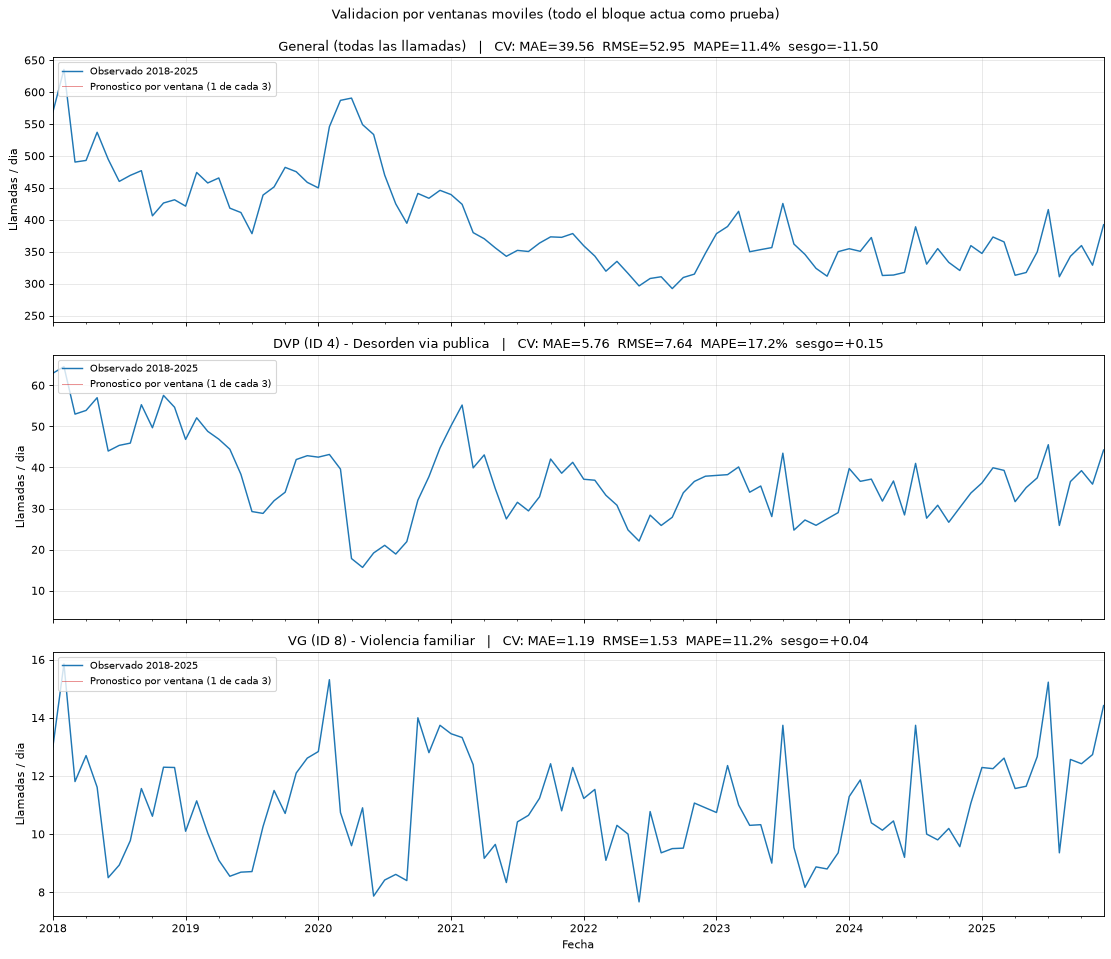

In [8]:
# ============================================================================
# 4) LA VALIDACION: VENTANAS MOVILES SOBRE EL BLOQUE COMPLETO
# ============================================================================
# No se reserva un tramo fijo. Para cada origen se entrena con el pasado y se
# proyectan 12 meses: cada anio actua como periodo a predecir en algun momento, y
# ninguna ventana usa informacion posterior a su origen.
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
for ax, n in zip(axes, SERIES):
    r = resultados[n]
    r["serie"].plot(ax=ax, label="Observado 2018-2025", color="#1f77b4", linewidth=1.3)
    # Se dibuja una de cada 3 ventanas para no repetir 49 ajustes por serie (la
    # metrica de la tabla SI usa todas). El dibujo es ilustrativo.
    cortes_plot = list(range(MIN_ENTRENAMIENTO, len(r["serie"]) - VENTANA_CV + 1))[::3]
    for k, corte in enumerate(cortes_plot):
        m = sm.tsa.statespace.SARIMAX(
            r["serie"].iloc[:corte], order=r["order"], seasonal_order=r["seasons"],
            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        pv = m.get_forecast(steps=VENTANA_CV).predicted_mean
        ax.plot(pv.index, pv.values, color="#d62728", alpha=0.5, linewidth=0.9,
                label="Pronostico por ventana (1 de cada 3)" if k == 0 else None)
    ax.set_title(f"{ETIQUETA[n]}   |   CV: MAE={r['mae']:.2f}  RMSE={r['rmse']:.2f}  "
                 f"MAPE={r['mape']:.1f}%  sesgo={r['sesgo']:+.2f}")
    ax.set_ylabel("Llamadas / dia")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Fecha")
fig.suptitle("Validacion por ventanas moviles (todo el bloque actua como prueba)", y=0.995)
plt.tight_layout()
plt.show()

tabla_metricas = pd.DataFrame({
    "orden": [f"SARIMAX{resultados[n]['order']} x {resultados[n]['seasons']}" for n in SERIES],
    "AIC": [round(resultados[n]["aic"], 2) for n in SERIES],
    "MAE (CV)": [round(resultados[n]["mae"], 2) for n in SERIES],
    "RMSE (CV)": [round(resultados[n]["rmse"], 2) for n in SERIES],
    "MAPE (CV) %": [round(resultados[n]["mape"], 2) for n in SERIES],
    "sesgo": [round(resultados[n]["sesgo"], 2) for n in SERIES],
    "descartados": [resultados[n]["n_degenerados"] for n in SERIES],
}, index=[ETIQUETA[n] for n in SERIES])
tabla_metricas


Total de llamadas estimado por anio:


,general,dvp,vg
anio,,,
2026,133598,14035,4488
2027,132864,13567,4394
2028,133166,13543,4404


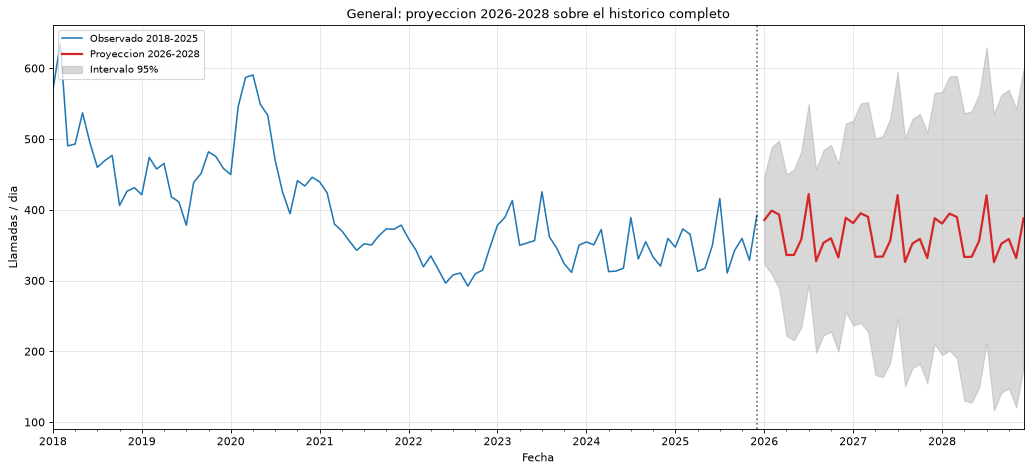

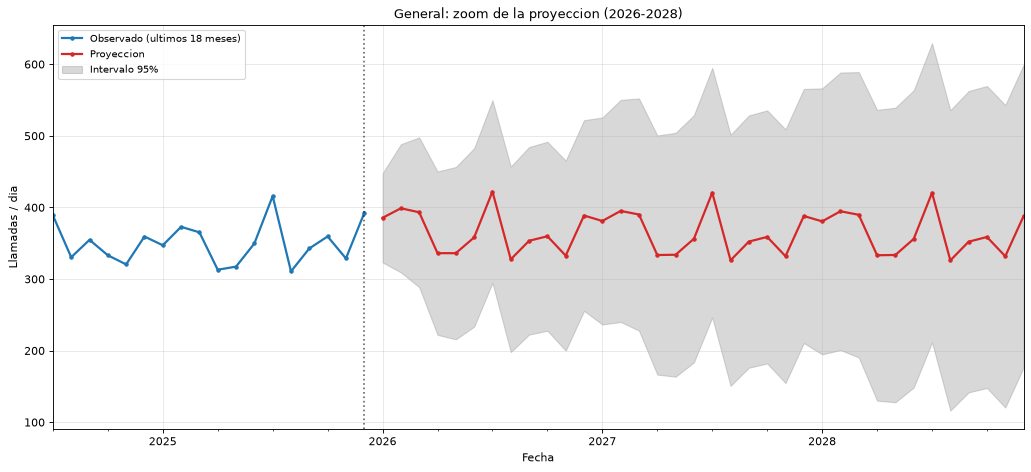

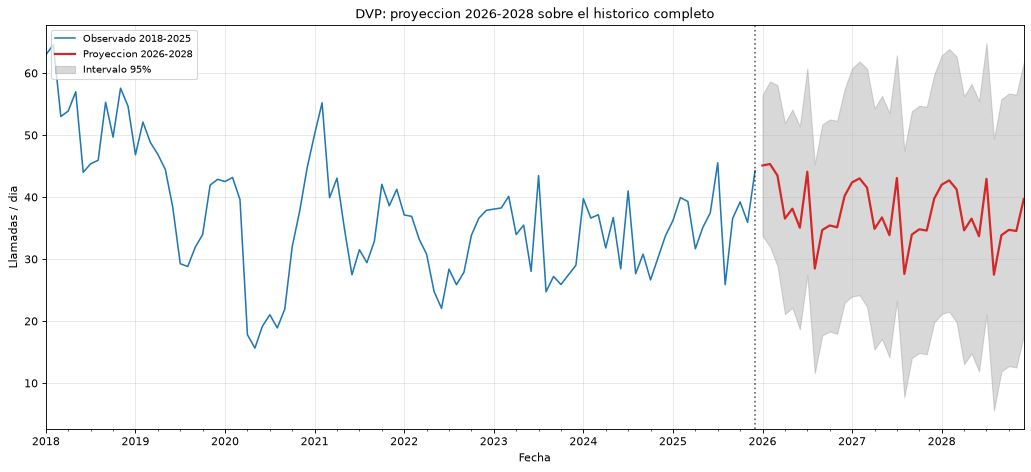

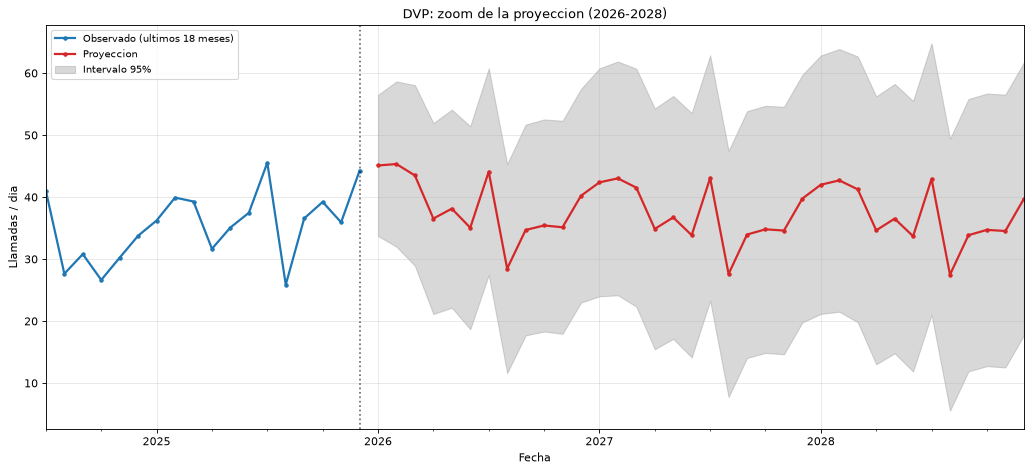

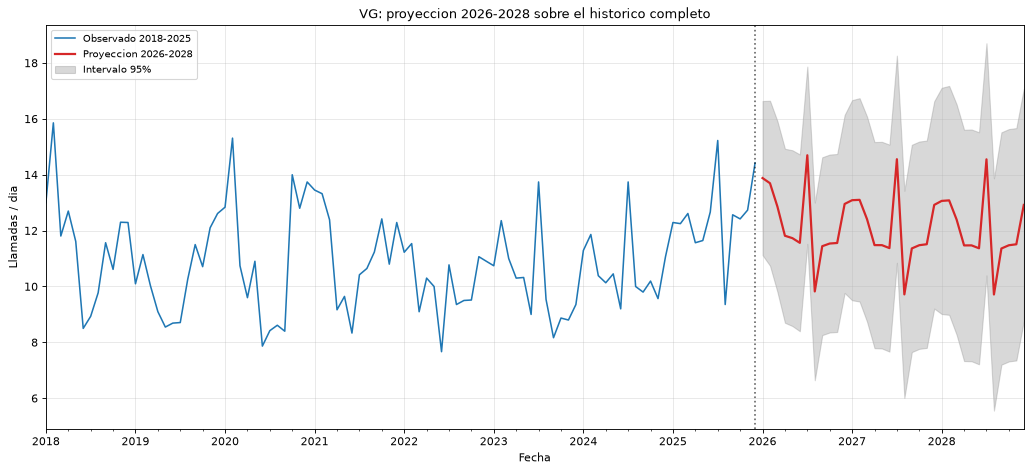

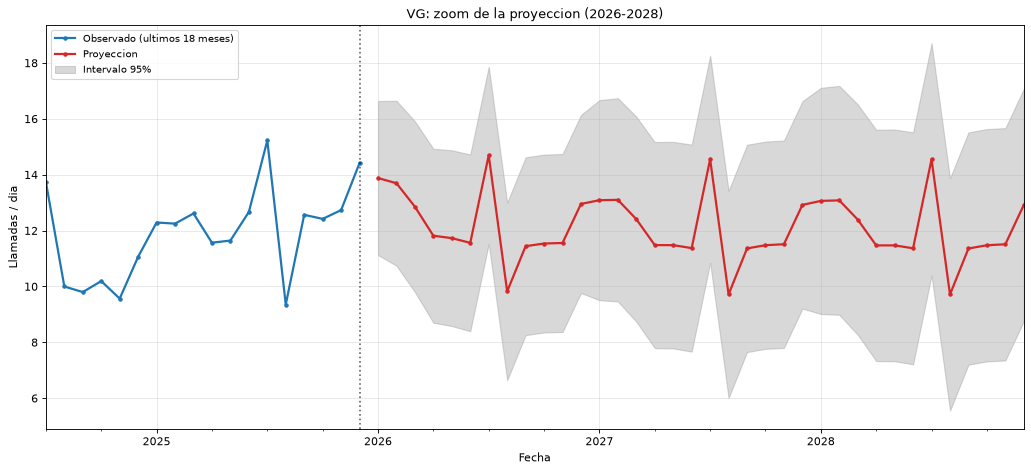

In [9]:
# ============================================================================
# 5) PROYECCION 2026-2028 (36 MESES) - una grafica por serie
# ============================================================================
# Produccion: se reentrena con TODO el historico 2018-2025 y se proyecta a 3 anios.
# Cada serie se dibuja en su propia figura para poder leerla por separado:
#   A) serie completa con la proyeccion al final
#   B) zoom de los ultimos 18 meses observados + la proyeccion
PASOS = 36
pronosticos = {}

for n in SERIES:
    r = resultados[n]
    modelo = sm.tsa.statespace.SARIMAX(
        r["serie"], order=r["order"], seasonal_order=r["seasons"],
        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = modelo.get_forecast(steps=PASOS)
    media = fc.predicted_mean
    ic = fc.conf_int()
    pronosticos[n] = (media, ic)

    etiqueta = ETIQUETA[n].split(" (")[0]

    # --- A) serie completa con la proyeccion --------------------------------
    fig, ax = plt.subplots(figsize=(13, 6))
    r["serie"].plot(ax=ax, label="Observado 2018-2025", color="#1f77b4", linewidth=1.4)
    media.plot(ax=ax, label="Proyeccion 2026-2028", color="#d62728", linewidth=2.0)
    ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color="gray", alpha=0.30,
                    label="Intervalo 95%")
    ax.axvline(r["serie"].index[-1], color="k", linestyle=":", alpha=0.6)
    ax.set_title(f"{etiqueta}: proyeccion 2026-2028 sobre el historico completo")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Llamadas / dia")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # --- B) zoom del tramo proyectado ---------------------------------------
    fig, ax = plt.subplots(figsize=(13, 6))
    r["serie"].iloc[-18:].plot(ax=ax, label="Observado (ultimos 18 meses)",
                               color="#1f77b4", linewidth=2.0, marker="o", markersize=3)
    media.plot(ax=ax, label="Proyeccion", color="#d62728", linewidth=2.0,
               marker="o", markersize=3)
    ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color="gray", alpha=0.30,
                    label="Intervalo 95%")
    ax.axvline(r["serie"].index[-1], color="k", linestyle=":", alpha=0.6)
    ax.set_title(f"{etiqueta}: zoom de la proyeccion (2026-2028)")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Llamadas / dia")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- totales anuales y mensuales -------------------------------------------
anual, mensual = {}, {}
for n in SERIES:
    media, ic = pronosticos[n]
    dias = media.index.days_in_month
    total = media.values * dias
    filas = pd.DataFrame({
        "promedio_diario": media.values.round(1),
        "ic95_inferior": ic.iloc[:, 0].values.round(1),
        "ic95_superior": ic.iloc[:, 1].values.round(1),
        "dias_del_mes": dias,
        "total_mensual": np.round(total, 0).astype(int),
    }, index=media.index)
    mensual[n] = filas
    anual[n] = filas.groupby(filas.index.year)["total_mensual"].sum()

tabla_anual = pd.DataFrame(anual)
tabla_anual.index.name = "anio"
print("Total de llamadas estimado por anio:")
tabla_anual


Detalle mensual del primer anio proyectado (promedio diario y total del mes):


,promedio_diario,ic95_inferior,ic95_superior,dias_del_mes,total_mensual
2026-01-01,385.5,323.2,447.8,31,11952
2026-02-01,398.9,309.3,488.4,28,11168
2026-03-01,393.3,288.7,497.9,31,12192
2026-04-01,336.2,222.1,450.3,30,10086
2026-05-01,336.2,215.8,456.5,31,10421
2026-06-01,358.2,233.6,482.8,30,10745
2026-07-01,422.3,294.7,549.8,31,13090
2026-08-01,327.5,198.0,457.1,31,10154
2026-09-01,353.5,222.5,484.4,30,10604
2026-10-01,359.8,227.8,491.8,31,11154


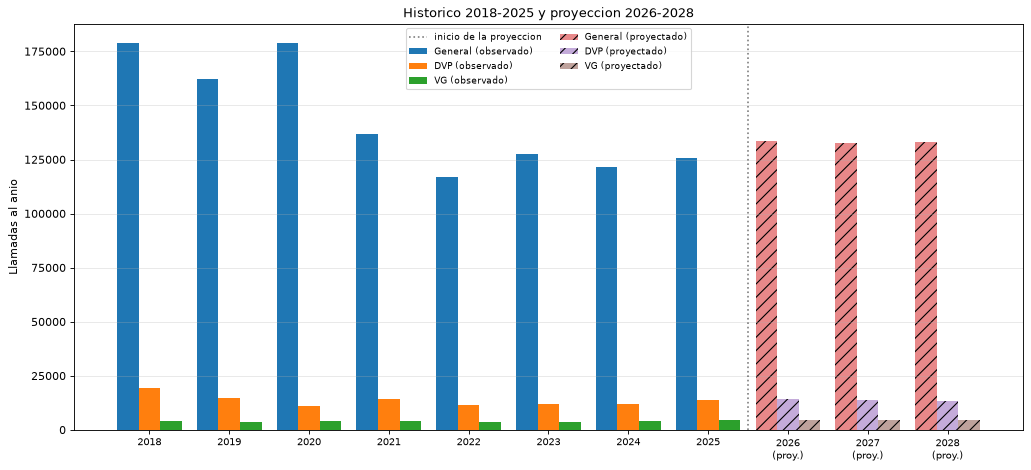

In [10]:
# ============================================================================
# 6) CONTEXTO HISTORICO Y LECTURA DE RESULTADOS
# ============================================================================
# Cada anio tiene 3 barras (una por serie). Las de 2018-2025 son observadas y las
# de 2026-2028 proyectadas. NO se desplaza el eje: las barras proyectadas van en
# su propio anio, que es lo que coincide con las etiquetas del eje.
fig, ax = plt.subplots(figsize=(13, 6))
historico = {n: datos[n].groupby("anio")["CANTIDAD"].sum() for n in SERIES}
anios_hist = sorted(historico["general"].index)
anios_proy = list(tabla_anual.index.values)
ancho = 0.27

for i, n in enumerate(SERIES):
    ax.bar([a - ancho + i * ancho for a in anios_hist], historico[n].values,
           width=ancho, label=f"{ETIQUETA[n].split(' (')[0]} (observado)")
for i, n in enumerate(SERIES):
    ax.bar([a - ancho + i * ancho for a in anios_proy],
           tabla_anual[n].values, width=ancho, alpha=0.55, hatch="//",
           label=f"{ETIQUETA[n].split(' (')[0]} (proyectado)")

# separacion visual entre el tramo observado y el proyectado
ax.axvline((max(anios_hist) + min(anios_proy)) / 2, color="k", linestyle=":",
           alpha=0.5, label="inicio de la proyeccion")
ax.set_xticks(list(anios_hist) + anios_proy)
ax.set_xticklabels([str(a) for a in anios_hist] + [f"{a}\n(proy.)" for a in anios_proy],
                   fontsize=9)
ax.set_ylabel("Llamadas al anio")
ax.set_title("Historico 2018-2025 y proyeccion 2026-2028")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("Detalle mensual del primer anio proyectado (promedio diario y total del mes):")
mensual["general"].head(12)


## 7. Cómo leer estos resultados

### Lo que sí es sólido

- Las tres series usan el mismo criterio: entre los **5 mejores por AIC** se elige el de
  **menor RMSE de validación cruzada**. Las cifras concretas las imprime la celda anterior.
- **VG (ID 8)** tiene el mejor ajuste absoluto (error en llamadas/día).
- **La serie general** es la más fiable en términos relativos (MAPE), porque tiene el mayor
  volumen y por tanto más margen de error absoluto tolerado.
- Las tres eligen **diferenciación estacional** (`D=1`), el tratamiento correcto para una
  serie con estacionalidad anual marcada.

### Una decisión importante de método

**No hay un tramo reservado como «holdout».** Se trabaja con el bloque 2018-2025 completo y
la capacidad predictiva se mide con **ventanas móviles**: para cada origen se entrena solo
con el pasado y se proyectan los 12 meses siguientes. Así cada año actúa como periodo a
predecir en algún momento, y ninguna predicción usa información futura.

Es más informativo que reservar 2024-2025: da decenas de evaluaciones en lugar de una, y no
depende de que un único tramo sea representativo. La contrapartida honesta es que no se
puede afirmar «el modelo nunca vio 2024-2025»; a cambio, cada ventana se evalúa como lo
haría un pronóstico real.

> **Mira el sesgo, no solo el error.** Si el sesgo es muy positivo, el modelo sobre-predice
> de forma sistemática. Ese era el problema de la versión anterior, que elegía por AIC
> modelos con `d=1` y se desviaba hacia arriba.

### Lo que hay que mirar con cuidado

1. **El intervalo se ensancha mucho a 36 meses.** Hacia 2028 el límite inferior del
   intervalo al 95 % puede volverse negativo. Eso **no significa** que se esperen llamadas
   negativas: significa que el modelo *no puede descartar* una caída fuerte tan lejos en el
   tiempo. **Usa 2026–2027 para decidir y 2028 como tendencia.**

2. **DVP es la serie más volátil.** Su error relativo (MAPE) es el más alto de las tres.
   Sus cifras deben tomarse como orientación de tendencia, no como valor comprometible.

3. **La proyección de VG es casi plana.** Es coherente con una serie estable, pero conviene
   saberlo antes de usarla para planificar.

### Estacionalidad: un patrón estructural

El patrón mensual se repite año tras año en el histórico: **agosto es el mes valle** y
**julio el pico**. Al ser estructural y no ruido, el modelo lo reproduce en la proyección.

> **Sobre agosto:** el agosto observado se hunde en 2023, 2024 y 2025 (≈40 % por debajo del
> resto de cada año), un artefacto del sistema de origen. Se excluye y se reconstruye con el
> mismo mes de años vecinos; por eso el agosto proyectado es más alto que el observado
> reciente.

---

## 8. Reproducibilidad

Este notebook se ejecuta de principio a fin en unos **12 segundos** y **no necesita SQL
Server**: solo los tres CSV del proyecto.

- **En local:** abre el notebook desde la carpeta del proyecto y ejecuta todo.
- **En Colab:** sube la carpeta de la demo a tu Drive, abre el `.ipynb` y ejecuta todo.

> La demo reproduce el mismo pipeline que la entrega final: misma rejilla AIC, mismo
> filtro de ajustes degenerados, mismo holdout y mismo horizonte de 36 meses. Las cifras
> pueden diferir en decimales porque aquí se reentrena en vivo.


In [12]:
# ============================================================================
# 9) RESUMEN DEL ORIGEN DE LOS DATOS
# ============================================================================
# La busqueda en Drive y la subida manual ya se resuelven en la celda de carga
# (celda 1). Aqui solo se deja constancia de donde se leyo cada archivo, que es
# util cuando alguien comparte una captura o reporta un problema.
print("Origen de cada serie:")
for n in SERIES:
    print(f"  {n:8s} -> {origenes[n]}")
if EN_COLAB:
    print("\nEjecutandose en Google Colab.")
else:
    print("\nEjecutandose en local.")


Origen de cada serie:
  general  -> C:\Prediccion2026\demo\datos_general.csv
  dvp      -> C:\Prediccion2026\demo\datos_dvp.csv
  vg       -> C:\Prediccion2026\demo\datos_vg.csv

Ejecutandose en local.
